# Прогнозирование прочности бетона
**Автор:** Поздин Марат Евгеньевич, ученик 11Б класса МБОУ лицей №7.
Цель: сравнить линейную регрессию и случайный лес на новых рецептурах.
Источник: Yeh, I. (1998), UCI, DOI: 10.24432/C5PK67, CC BY 4.0.
Все дозировки указаны в кг/м³, возраст в сутках, прочность в МПа.

## Запуск
Локально: установите зависимости из `requirements.txt`, откройте ноутбук в папке проекта и выполните все ячейки. В Google Colab сначала выполните `%pip install xlrd scikit-learn==1.9.1`, затем запустите ячейки. При отсутствии исходного файла первая секция скачает его из UCI.

In [1]:
from pathlib import Path
import io
import json
import hashlib
import zipfile
import urllib.request
import platform
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
for directory in ['data', 'results', 'figures']:
    (ROOT / directory).mkdir(exist_ok=True)
SEED = 42
COLS = ['cement', 'slag', 'fly_ash', 'water', 'superplasticizer',
        'coarse_aggregate', 'fine_aggregate', 'age', 'strength']
LABELS = ['Цемент', 'Шлак', 'Зола-унос', 'Вода', 'Суперпластификатор',
          'Крупный заполнитель', 'Мелкий заполнитель', 'Возраст']
COLORS = {'Среднее': '#94A3B8', 'Линейная регрессия': '#D97742', 'Случайный лес': '#167D8D'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.facecolor': 'white',
                     'savefig.facecolor': 'white'})
def savefig(name):
    plt.savefig(ROOT / 'figures' / f'{name}.png', dpi=180, bbox_inches='tight')
    if 'ipykernel' in sys.modules:
        from IPython.display import display, Image
        display(Image(filename=str(ROOT / 'figures' / f'{name}.png')))
    plt.close()

## 1. Загрузка и контроль качества
Оригинальный файл сохраняем локально. Повторный запуск не требует интернета.
Удаляем только полные повторы строк. Разные измерения одного состава сохраняем.

In [2]:
xls = ROOT / 'data' / 'Concrete_Data.xls'
if not xls.exists():
    url = 'https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip'
    with urllib.request.urlopen(url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    member = next(n for n in archive.namelist() if n.endswith('Concrete_Data.xls'))
    xls.write_bytes(archive.read(member))
raw = pd.read_excel(xls, engine='xlrd')
assert raw.shape == (1030, 9), f'Неожиданная форма данных: {raw.shape}'
raw.columns = COLS
raw.insert(0, 'row_id', np.arange(1, len(raw) + 1))
assert not raw[COLS].isna().any().any(), 'Обнаружены пропуски'
assert (raw[COLS] >= 0).all().all(), 'Обнаружены отрицательные значения'
df = raw.drop_duplicates(subset=COLS).copy()
df.to_csv(ROOT / 'data' / 'concrete_clean.csv', index=False)
df[COLS].describe().to_csv(ROOT / 'results' / 'descriptive_statistics.csv')
quality = {'raw_rows': len(raw), 'clean_rows': len(df),
           'duplicates_removed': len(raw) - len(df), 'missing_values': 0,
           'sha256_xls': hashlib.sha256(xls.read_bytes()).hexdigest()}
print(json.dumps(quality, ensure_ascii=False, indent=2))
print(df[COLS].describe().round(2).to_string())

{
  "raw_rows": 1030,
  "clean_rows": 1005,
  "duplicates_removed": 25,
  "missing_values": 0,
  "sha256_xls": "710076c66b9ca3f8050e7942f3dcbdbe04013534daeb0077ffd3079a52d8e0c4"
}
        cement     slag  fly_ash    water  superplasticizer  coarse_aggregate  fine_aggregate      age  strength
count  1005.00  1005.00  1005.00  1005.00           1005.00           1005.00         1005.00  1005.00   1005.00
mean    278.63    72.04    55.54   182.07              6.03            974.38          772.69    45.86     35.25
std     104.35    86.17    64.21    21.34              5.92             77.58           80.34    63.73     16.28
min     102.00     0.00     0.00   121.75              0.00            801.00          594.00     1.00      2.33
25%     190.68     0.00     0.00   166.61              0.00            932.00          724.30     7.00     23.52
50%     265.00    20.00     0.00   185.70              6.10            968.00          780.00    28.00     33.80
75%     349.00   142.50   118

## 2. Разбиение без пересечения рецептур
Рецептура — семь компонентов без возраста. Все наблюдения одной рецептуры
попадают в одну часть выборки, даже если отличаются возрастом или прочностью.
Это более строгая задача, чем случайное разбиение строк: прогноз для новых составов.
20% групп откладываем в test. Test не участвует в выборе параметров.

In [3]:
X, y = df[COLS[:-1]], df['strength']
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X.iloc[:, :7]))[0], index=df.index)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(g_train).isdisjoint(g_test)
split_info = {'train_rows': len(train_idx), 'test_rows': len(test_idx),
              'total_recipes': groups.nunique(), 'train_recipes': g_train.nunique(),
              'test_recipes': g_test.nunique(), 'recipe_overlap': 0}
partition = df[['row_id']].copy()
partition['recipe_group'] = groups
partition['split'] = np.where(partition.index.isin(X_test.index), 'test', 'train')
partition.to_csv(ROOT / 'results' / 'split.csv', index=False)
print(split_info)

{'train_rows': 799, 'test_rows': 206, 'total_recipes': 428, 'train_recipes': 342, 'test_recipes': 86, 'recipe_overlap': 0}


## 3. Разведочный анализ обучающей выборки
До оценки моделей графики строим только по train.
Корреляция описывает связь в данных, но не доказывает причинное влияние.

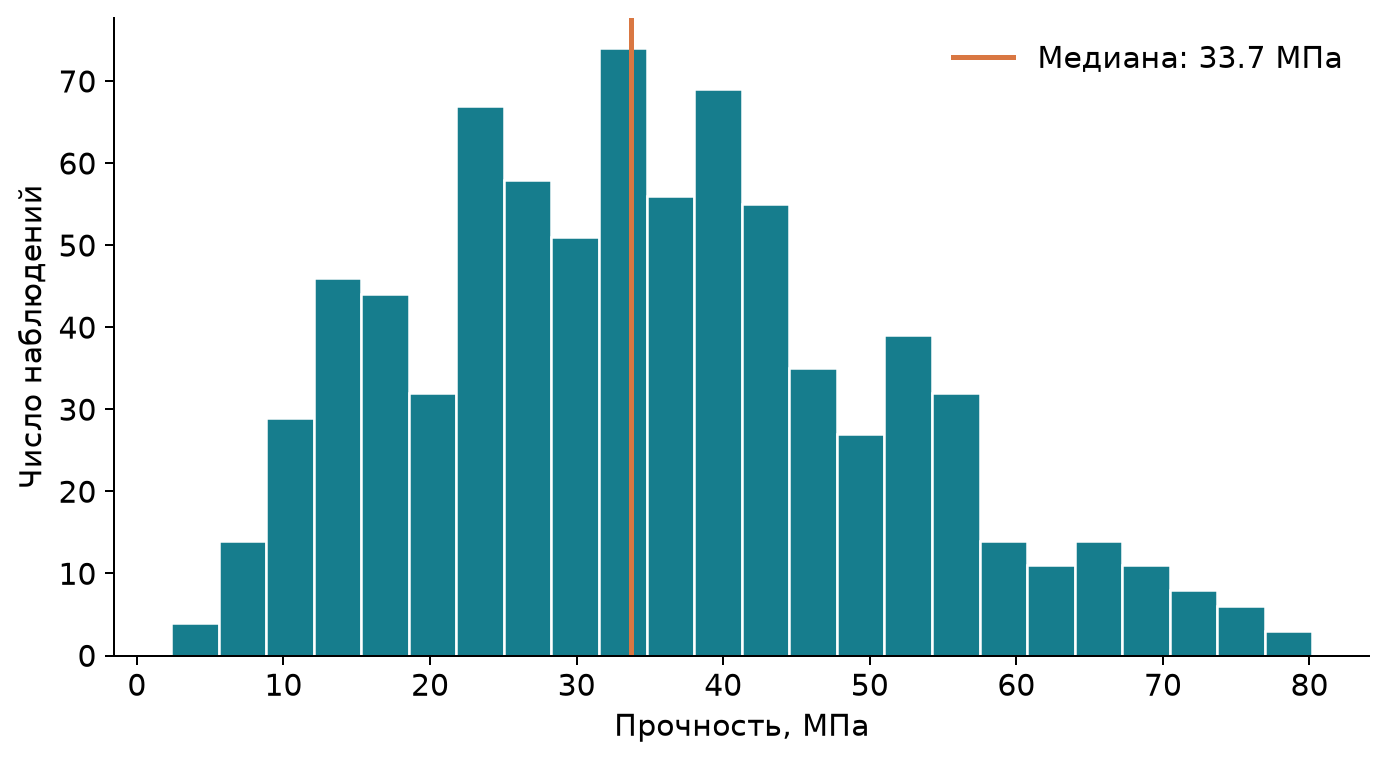

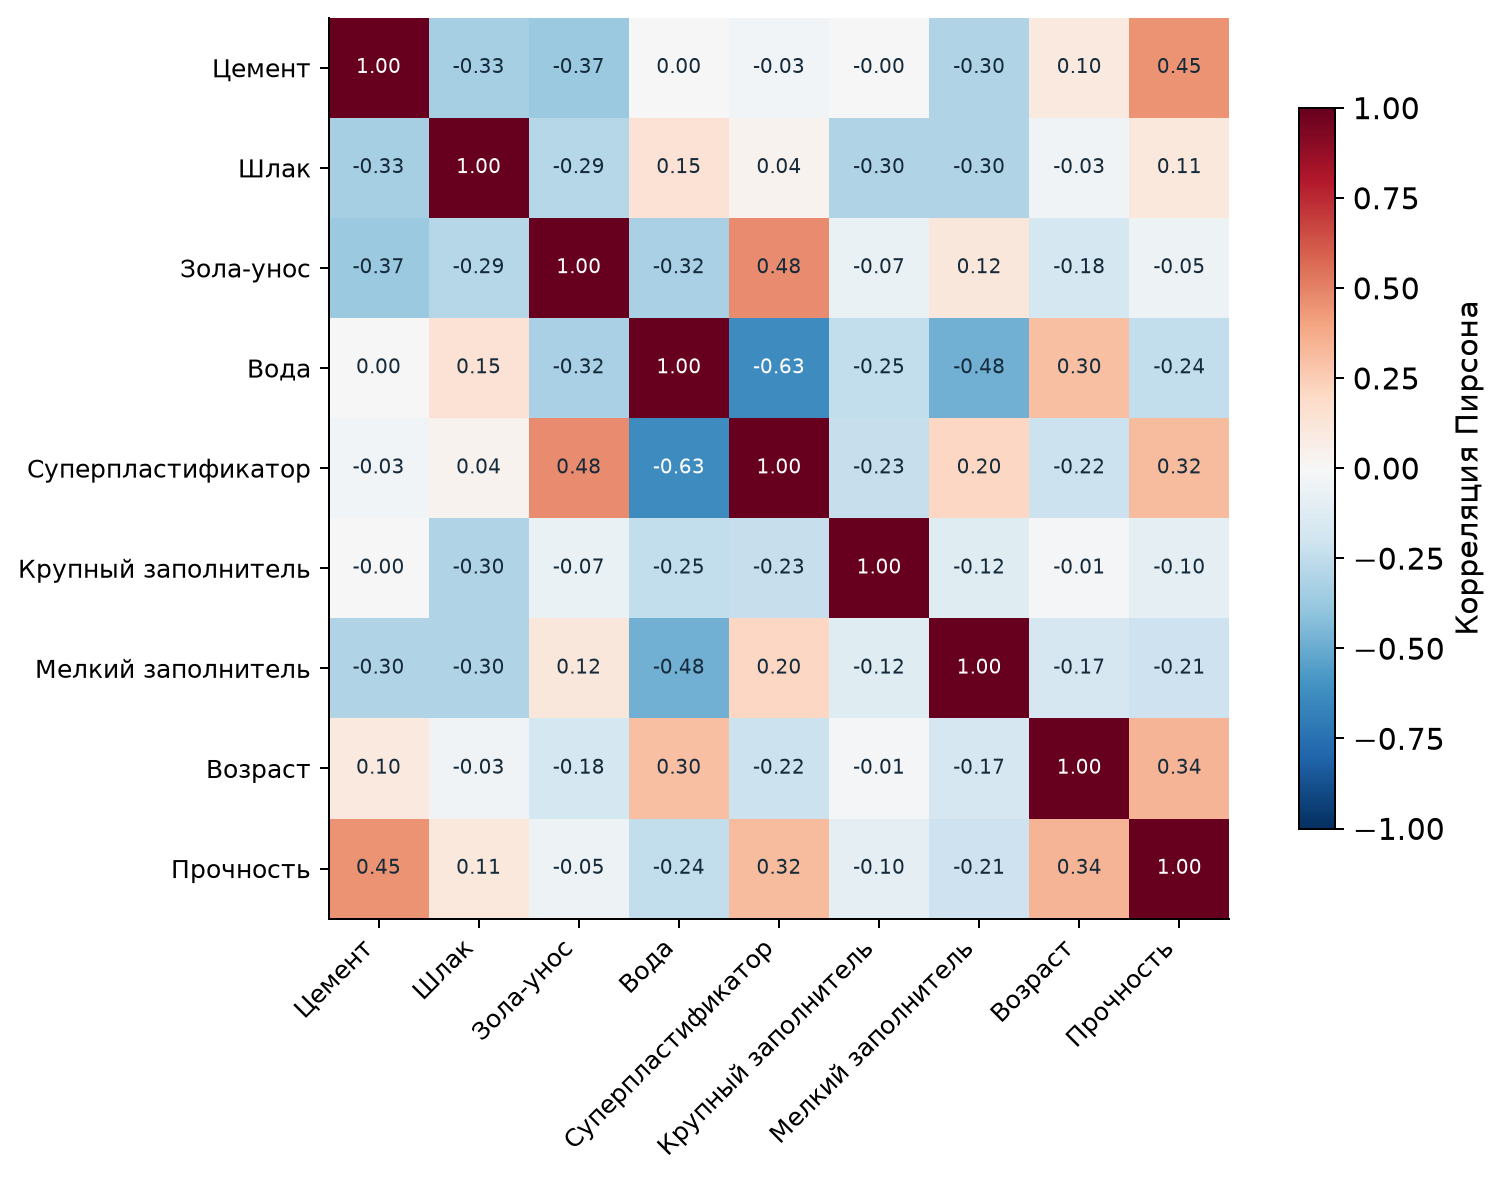

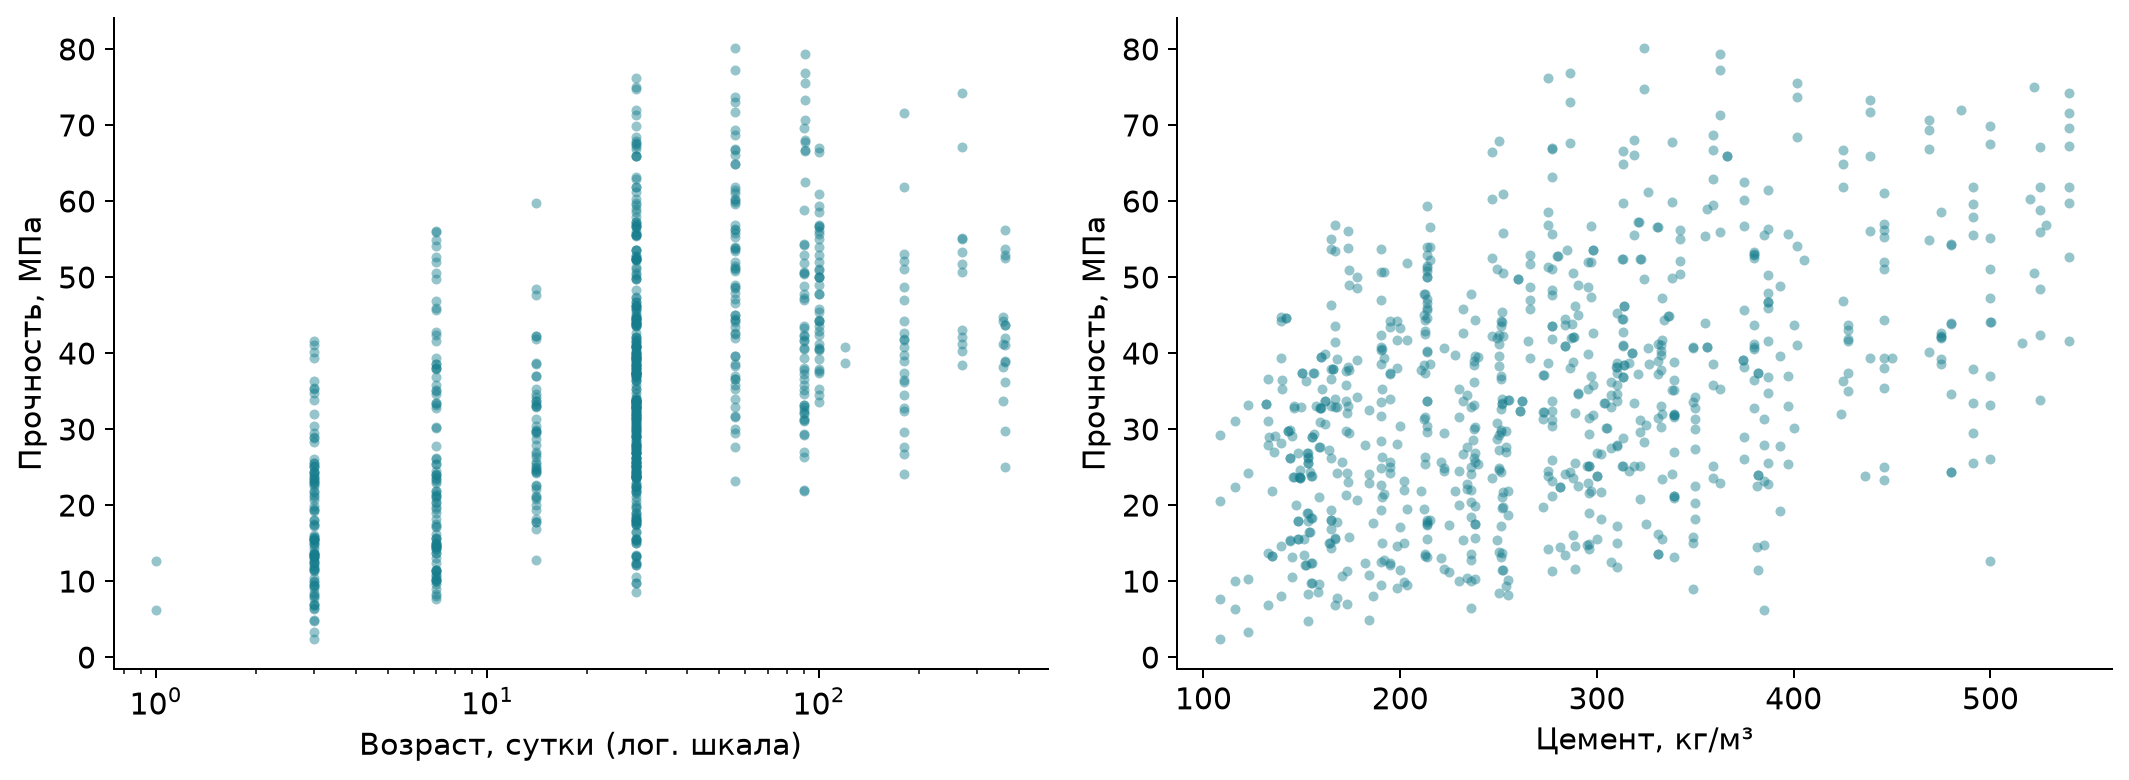

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(y_train, bins=24, color='#167D8D', edgecolor='white')
ax.set(xlabel='Прочность, МПа', ylabel='Число наблюдений')
ax.axvline(y_train.median(), color='#D97742', lw=2,
           label=f'Медиана: {y_train.median():.1f} МПа')
ax.legend(frameon=False)
savefig('01_strength_distribution')

corr = X_train.assign(strength=y_train).corr()
fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
names = LABELS + ['Прочность']
ax.set_xticks(range(9), names, rotation=45, ha='right', fontsize=10)
ax.set_yticks(range(9), names, fontsize=10)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr.iloc[i,j]) > .6 else '#152B3B')
fig.colorbar(im, ax=ax, shrink=.8, label='Корреляция Пирсона')
savefig('02_correlations')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feature, xlabel in zip(axes, ['age', 'cement'], ['Возраст, сутки (лог. шкала)', 'Цемент, кг/м³']):
    ax.scatter(X_train[feature], y_train, s=16, alpha=.45, color='#167D8D', linewidth=0)
    ax.set(xlabel=xlabel, ylabel='Прочность, МПа')
axes[0].set_xscale('log')
fig.tight_layout()
savefig('03_age_cement')

## 4. Модели и настройка
DummyRegressor предсказывает среднее train и задаёт отправную точку.
Линейная регрессия оценивает сумму вкладов восьми признаков.
StandardScaler обучается внутри Pipeline на каждом фолде, без утечки.
Случайный лес усредняет деревья и может учитывать нелинейности и взаимодействия.
Выбираем параметры по RMSE в GroupKFold из пяти фолдов, только внутри train.

In [5]:
cv = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
for a, b in cv:
    assert set(g_train.iloc[a]).isdisjoint(g_train.iloc[b])
models = {'Среднее': DummyRegressor(strategy='mean'),
          'Линейная регрессия': make_pipeline(StandardScaler(), LinearRegression())}
search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
    {'max_depth': [None, 15], 'min_samples_leaf': [1, 3], 'max_features': [0.8, 1.0]},
    scoring='neg_root_mean_squared_error', cv=cv, n_jobs=2, refit=True,
    return_train_score=True)
search.fit(X_train, y_train)
models['Случайный лес'] = search.best_estimator_
pd.DataFrame(search.cv_results_).to_csv(ROOT / 'results' / 'grid_search.csv', index=False)
cv_records = []
for name, model in models.items():
    if name == 'Случайный лес':
        scores = np.array([-search.cv_results_[f'split{i}_test_score'][search.best_index_] for i in range(5)])
    else:
        scores = -cross_val_score(model, X_train, y_train, scoring='neg_root_mean_squared_error', cv=cv)
    cv_records.append({'model': name, 'cv_rmse_mean': scores.mean(), 'cv_rmse_std': scores.std(),
                       **{f'fold_{i+1}': value for i, value in enumerate(scores)}})
    model.fit(X_train, y_train)
cv_results = pd.DataFrame(cv_records)
cv_results.to_csv(ROOT / 'results' / 'cross_validation.csv', index=False)
print('Лучшие параметры леса:', search.best_params_)
print(cv_results.round(3).to_string(index=False))

Лучшие параметры леса: {'max_depth': 15, 'max_features': 0.8, 'min_samples_leaf': 1}
             model  cv_rmse_mean  cv_rmse_std  fold_1  fold_2  fold_3  fold_4  fold_5
           Среднее        15.790        0.696  15.187  15.875  16.625  14.824  16.440
Линейная регрессия        10.334        0.716  10.044  10.364  11.451   9.248  10.561
     Случайный лес         5.959        0.836   5.991   5.629   7.397   4.813   5.966


## 5. Единственная итоговая оценка на test
MAE — средняя абсолютная ошибка, RMSE сильнее штрафует большие промахи.
Обе метрики измеряются в МПа, меньше — лучше. R² сравнивает сумму квадратов
ошибок с прогнозом среднего test. R² может быть отрицательным.
Разбор test ниже — диагностика, после неё модели больше не перенастраиваем.

             model    MAE   RMSE     R2  train_RMSE  max_abs_error  cv_rmse_mean  cv_rmse_std
           Среднее 14.476 18.016 -0.006      15.800         47.634        15.790        0.696
Линейная регрессия  8.678 10.792  0.639      10.127         34.751        10.334        0.716
     Случайный лес  4.616  6.599  0.865       1.815         27.218         5.959        0.836


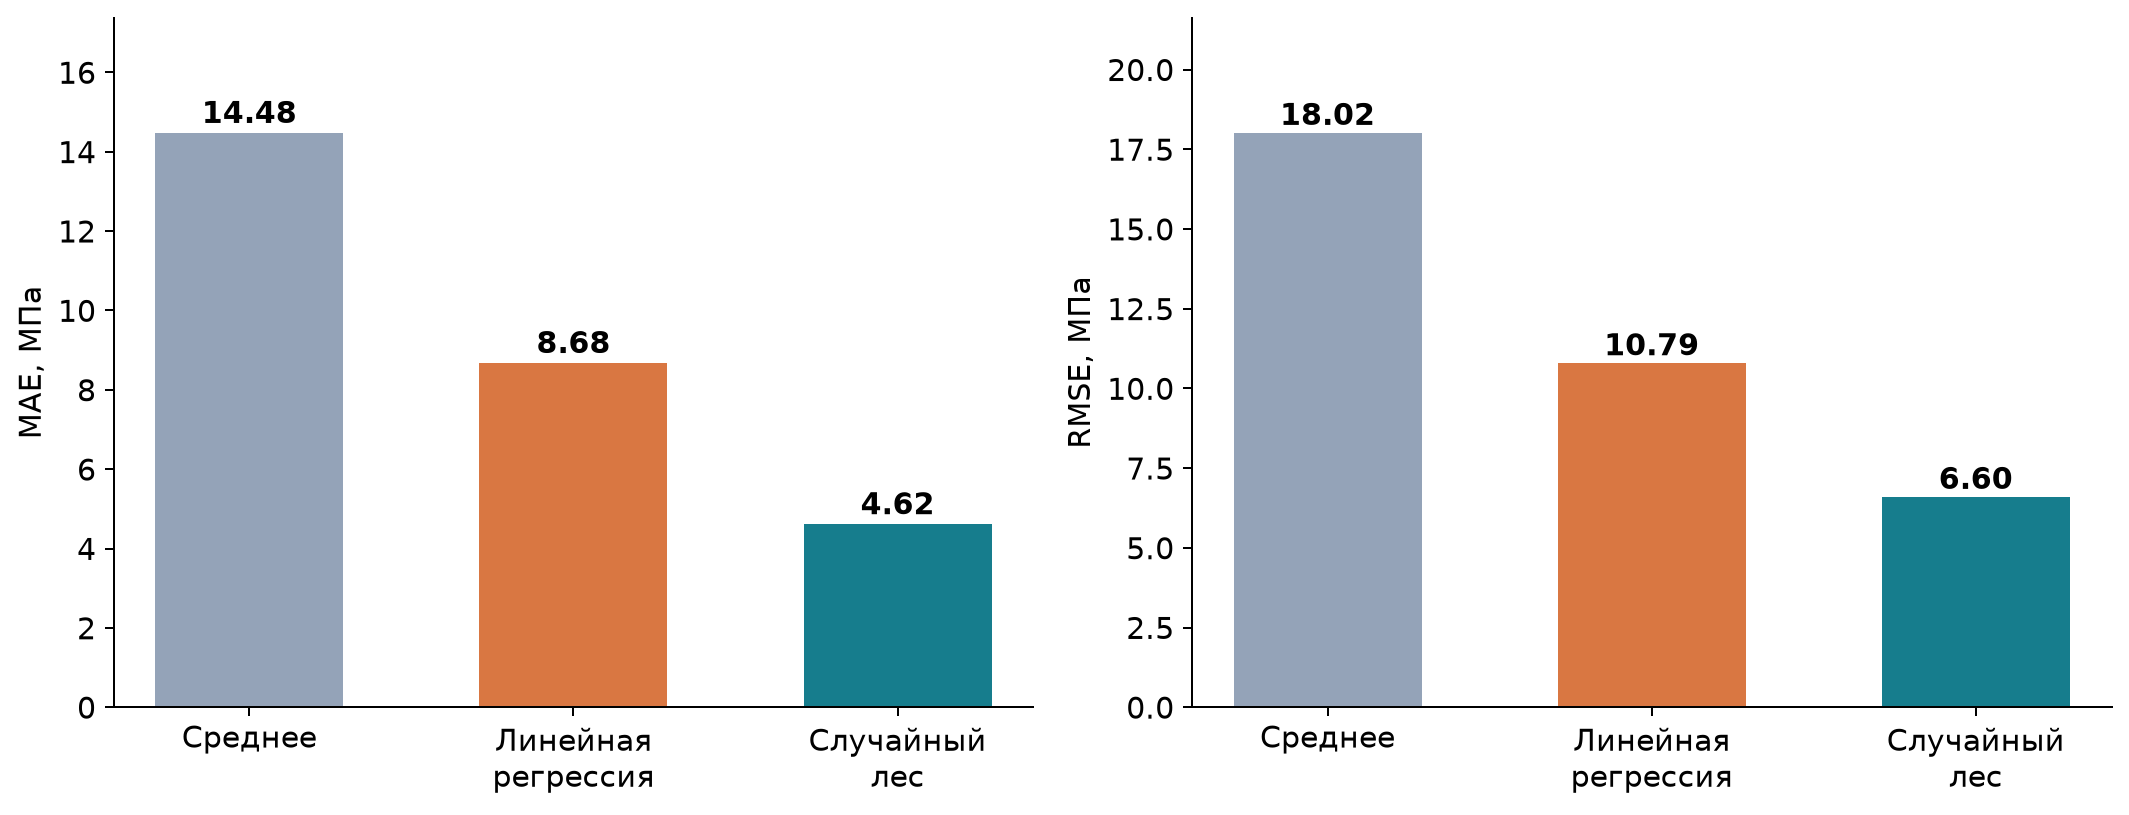

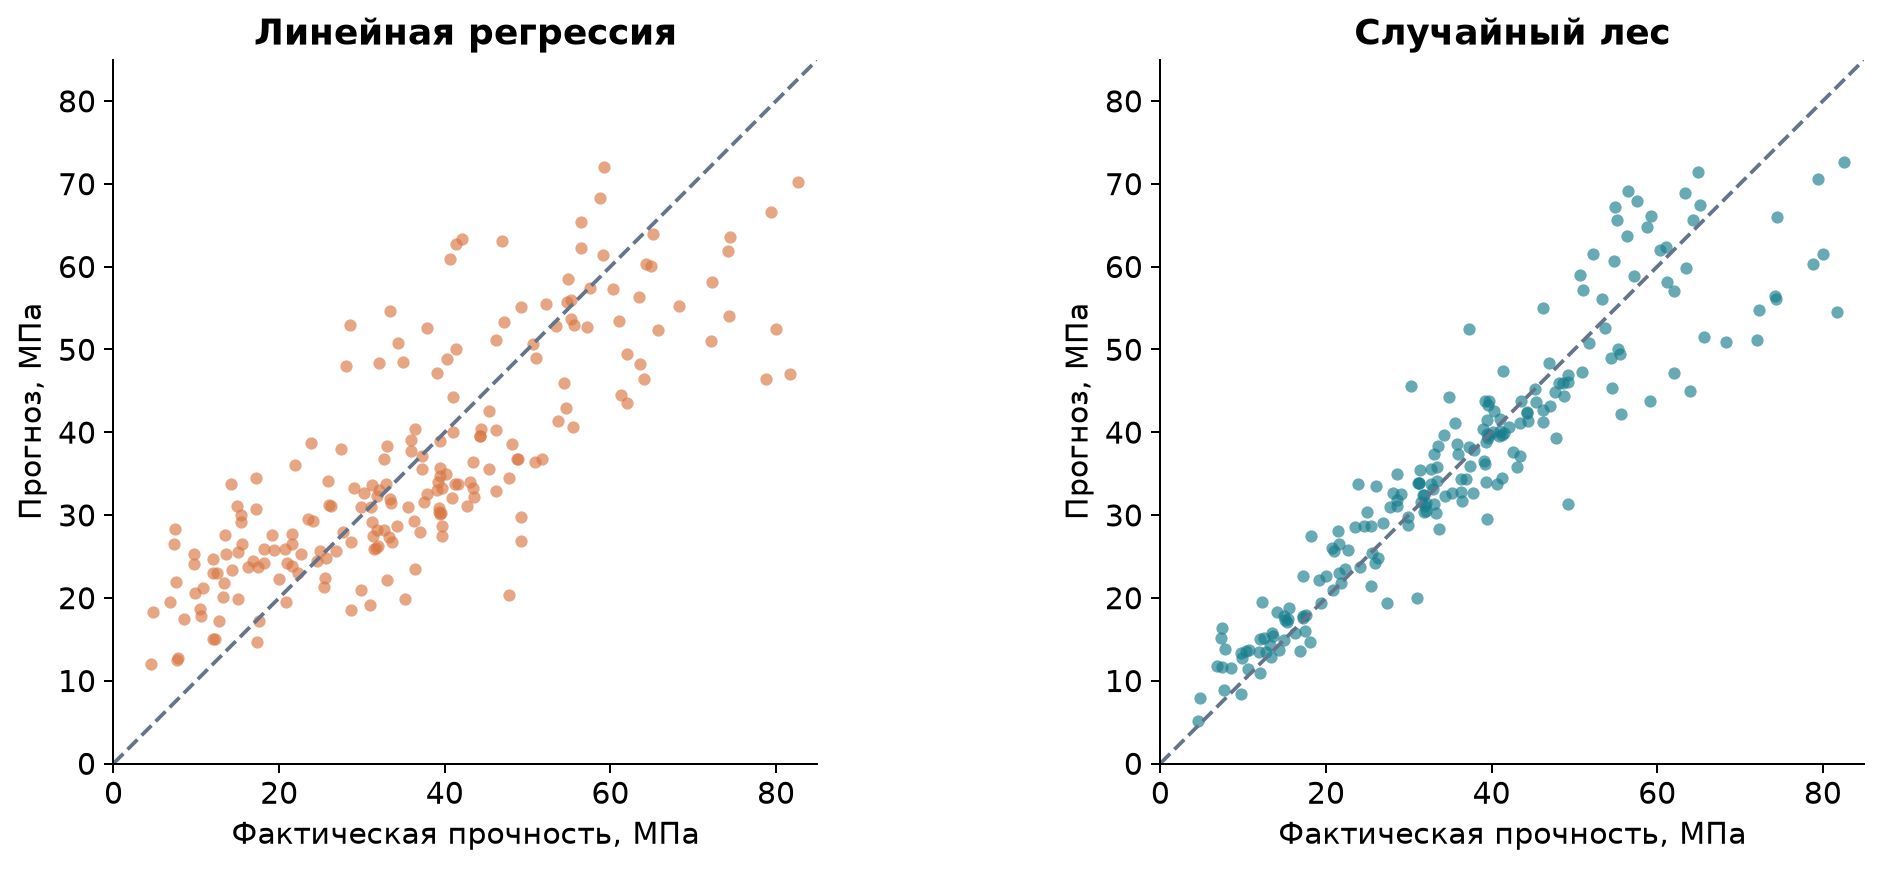

In [6]:
records, predictions = [], {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    records.append({'model': name, 'MAE': mean_absolute_error(y_test, pred),
                    'RMSE': root_mean_squared_error(y_test, pred), 'R2': r2_score(y_test, pred),
                    'train_RMSE': root_mean_squared_error(y_train, model.predict(X_train)),
                    'max_abs_error': np.abs(y_test.to_numpy()-pred).max()})
metrics = pd.DataFrame(records).merge(cv_results[['model', 'cv_rmse_mean', 'cv_rmse_std']], on='model')
metrics.to_csv(ROOT / 'results' / 'metrics.csv', index=False)
print(metrics.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    bars = ax.bar(range(3), metrics[metric], color=list(COLORS.values()), width=.58)
    ax.set_xticks(range(3), ['Среднее', 'Линейная\nрегрессия', 'Случайный\nлес'])
    ax.set(ylabel=f'{metric}, МПа', ylim=(0, metrics[metric].max()*1.2))
    for bar, value in zip(bars, metrics[metric]):
        ax.text(bar.get_x()+bar.get_width()/2, value+.25, f'{value:.2f}', ha='center', fontweight='bold')
fig.tight_layout()
savefig('04_metrics')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Линейная регрессия', 'Случайный лес']):
    ax.scatter(y_test, predictions[name], color=COLORS[name], alpha=.65, s=24, linewidth=0)
    ax.plot([0, 85], [0, 85], '--', color='#64748B', lw=1.5)
    ax.set(xlabel='Фактическая прочность, МПа', ylabel='Прогноз, МПа', title=name, xlim=(0,85), ylim=(0,85))
    ax.set_aspect('equal')
fig.tight_layout()
savefig('05_predictions')

## 6. Самые большие ошибки и проверяемые объяснения
Знак ошибки: прогноз минус факт. Положительная ошибка — завышение прочности.
Для каждого промаха ищем ближайшее наблюдение train по восьми стандартизованным
признакам. Это диагностическая подсказка, а не доказательство причины ошибки.


Крупнейшие ошибки: linear
 row_id  age  strength  pred_linear  error_linear  nearest_train_row  nearest_distance  nearest_strength
    382   28     81.75        47.00        -34.75                357              1.71             63.14
    384   28     78.80        46.47        -32.33                402              1.10             58.52
     15   28     47.81        20.33        -27.48                  9              0.57             45.85
      1   28     79.99        52.50        -27.48                  2              0.20             61.89
     86    3     28.60        52.89         24.29                404              1.80             59.00
     54   90     49.19        26.90        -22.29                  6              0.57             47.03
     80    3     41.30        62.71         21.41                 77              1.76             40.20
     73    3     33.40        54.65         21.26                 74              1.56             36.30
    793  360     42.13      

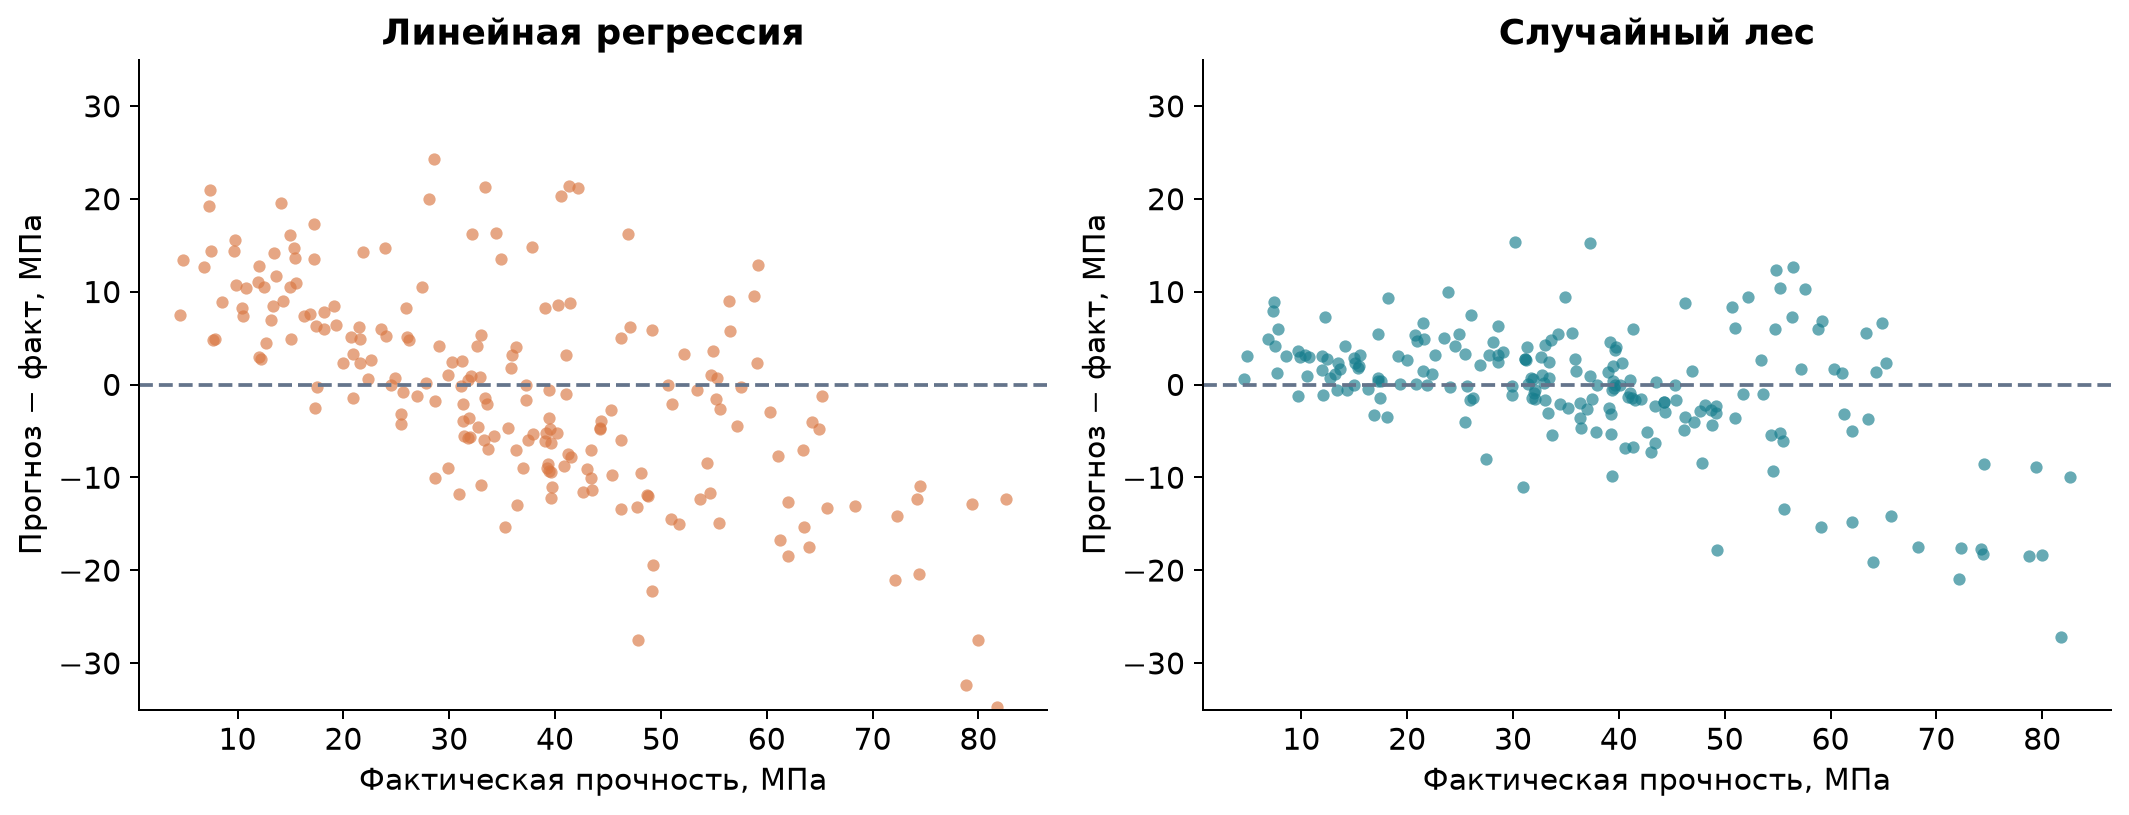

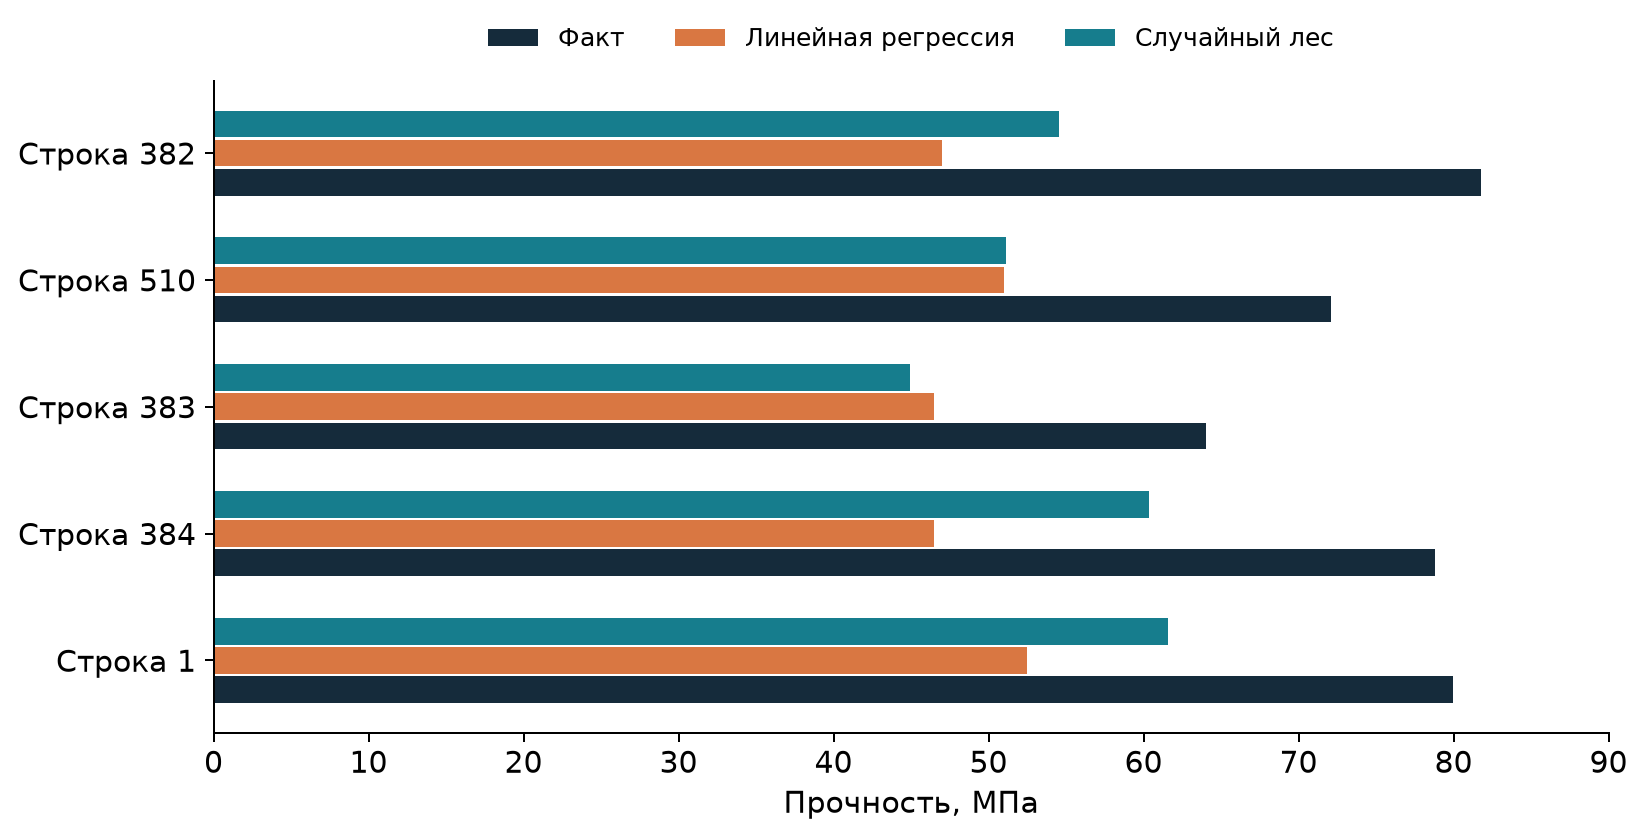

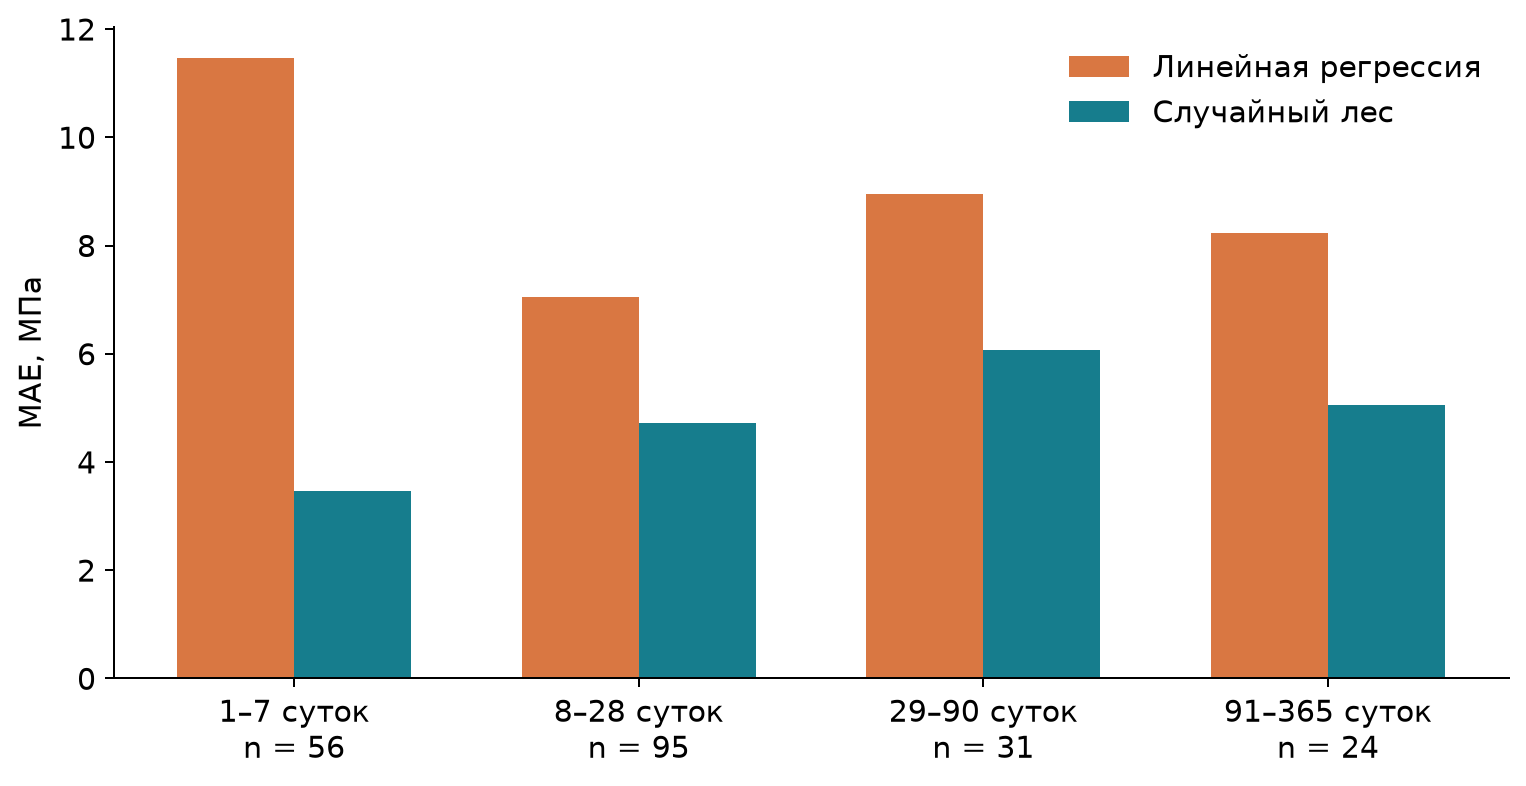

In [7]:
errors = df.loc[X_test.index].copy()
errors['pred_linear'] = predictions['Линейная регрессия']
errors['pred_forest'] = predictions['Случайный лес']
errors['error_linear'] = errors['pred_linear'] - errors['strength']
errors['error_forest'] = errors['pred_forest'] - errors['strength']
errors['abs_error_linear'] = errors['error_linear'].abs()
errors['abs_error_forest'] = errors['error_forest'].abs()
scaler = StandardScaler().fit(X_train)
nn = NearestNeighbors(n_neighbors=1).fit(scaler.transform(X_train))
dist, neighbor_idx = nn.kneighbors(scaler.transform(X_test))
neighbors = df.loc[X_train.index].iloc[neighbor_idx[:, 0]]
errors['nearest_train_row'] = neighbors['row_id'].to_numpy()
errors['nearest_distance'] = dist[:, 0]
errors['nearest_strength'] = neighbors['strength'].to_numpy()
errors.to_csv(ROOT / 'results' / 'test_predictions.csv', index=False)
for key in ['linear', 'forest']:
    top = errors.nlargest(10, f'abs_error_{key}')
    top.to_csv(ROOT / 'results' / f'top10_errors_{key}.csv', index=False)
    print(f'\nКрупнейшие ошибки: {key}')
    print(top[['row_id','age','strength',f'pred_{key}',f'error_{key}','nearest_train_row','nearest_distance','nearest_strength']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
for ax, name, key in zip(axes, ['Линейная регрессия', 'Случайный лес'], ['linear','forest']):
    ax.scatter(errors['strength'], errors[f'error_{key}'], s=24, alpha=.65, color=COLORS[name], linewidth=0)
    ax.axhline(0, ls='--', color='#64748B')
    ax.set(xlabel='Фактическая прочность, МПа', ylabel='Прогноз − факт, МПа', title=name, ylim=(-35,35))
fig.tight_layout()
savefig('06_residuals')

top5 = errors.nlargest(5, 'abs_error_forest').sort_values('abs_error_forest')
fig, ax = plt.subplots(figsize=(10, 4.7))
pos = np.arange(len(top5))
for offset, col, label, color in [(-.23,'strength','Факт','#152B3B'),
                                (0,'pred_linear','Линейная регрессия','#D97742'),
                                (.23,'pred_forest','Случайный лес','#167D8D')]:
    ax.barh(pos+offset, top5[col], height=.21, label=label, color=color)
ax.set_yticks(pos, [f'Строка {i}' for i in top5['row_id']])
ax.set(xlabel='Прочность, МПа', xlim=(0,90))
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(.5, 1.01), ncol=3, fontsize=10)
savefig('07_top_errors')

errors['age_group'] = pd.cut(errors['age'], bins=[0,7,28,90,400], labels=['1–7','8–28','29–90','91–365'])
age_errors = errors.groupby('age_group', observed=True).agg(n=('row_id','size'),
    mae_linear=('abs_error_linear','mean'), mae_forest=('abs_error_forest','mean'))
age_errors.to_csv(ROOT / 'results' / 'errors_by_age.csv')
fig, ax = plt.subplots(figsize=(10, 4.7))
pos = np.arange(len(age_errors))
ax.bar(pos-.17, age_errors['mae_linear'], width=.34, label='Линейная регрессия', color='#D97742')
ax.bar(pos+.17, age_errors['mae_forest'], width=.34, label='Случайный лес', color='#167D8D')
ax.set_xticks(pos, [f'{i} суток\nn = {n}' for i,n in zip(age_errors.index, age_errors['n'])])
ax.set(ylabel='MAE, МПа')
ax.legend(frameon=False)
savefig('08_errors_by_age')

## 7. Важность признаков
Переставляем один признак в test и измеряем рост RMSE. 20 повторений,
фиксированный seed. Планки показывают стандартное отклонение перестановок,
а не доверительный интервал. Коррелирующие компоненты могут делить важность.
Отрицательная оценка означает, что перестановка случайно улучшила метрику.

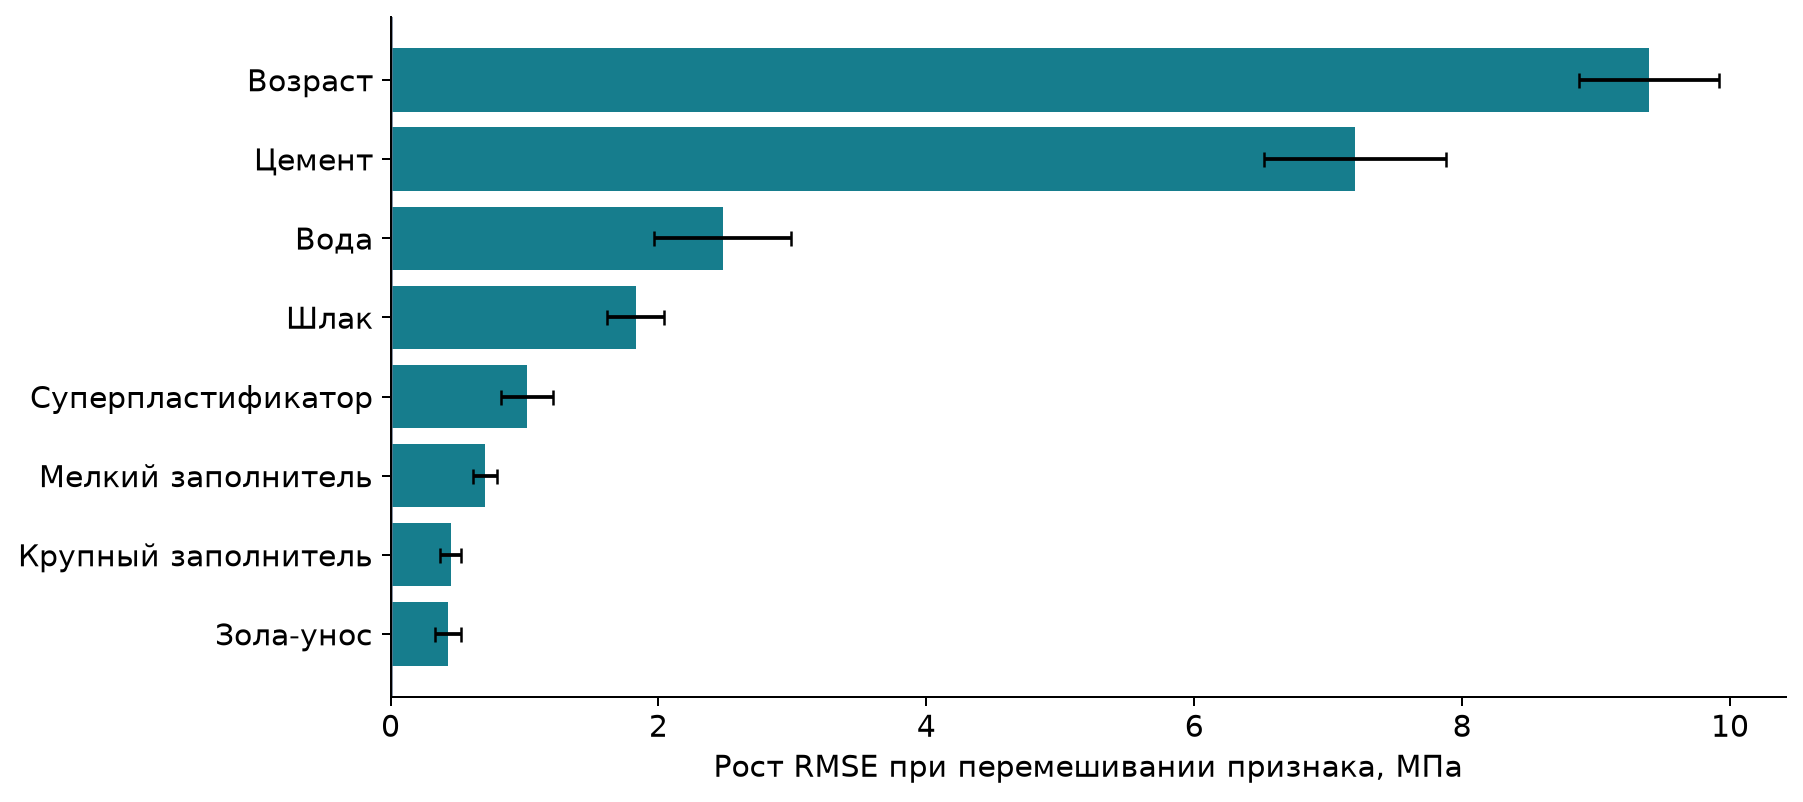

In [8]:
importance = permutation_importance(models['Случайный лес'], X_test, y_test,
    scoring='neg_root_mean_squared_error', n_repeats=20, random_state=SEED, n_jobs=2)
imp = pd.DataFrame({'feature': COLS[:-1], 'label': LABELS,
                    'mean': importance.importances_mean, 'std': importance.importances_std}).sort_values('mean')
imp.to_csv(ROOT / 'results' / 'permutation_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(10, 4.9))
ax.barh(imp['label'], imp['mean'], xerr=imp['std'], color='#167D8D', capsize=3)
ax.axvline(0, color='#64748B', lw=1)
ax.set(xlabel='Рост RMSE при перемешивании признака, МПа')
savefig('09_importance')

## 8. Итоги и ограничения
Качество относится к одному фиксированному тесту с новыми точными рецептурами.
Почти одинаковые составы могут оставаться по разные стороны разбиения.
Датасет не содержит температуру, условия твердения и подробности испытаний.
По этим данным нельзя доказать, что именно вызвало отдельный промах.
После разбора test следующий цикл улучшений потребует новой независимой проверки.

In [9]:
linear = metrics.set_index('model').loc['Линейная регрессия']
forest = metrics.set_index('model').loc['Случайный лес']
summary = {'quality': quality, 'split': split_info, 'seed': SEED,
           'best_forest_params': search.best_params_, 'n_estimators': 300,
           'rmse_reduction_pct': float(100 * (1-forest['RMSE']/linear['RMSE'])),
           'metrics': metrics.to_dict(orient='records'),
           'top3_forest': errors.nlargest(3,'abs_error_forest').to_dict(orient='records'),
           'train_target_range': [float(y_train.min()),float(y_train.max())],
           'versions': {'python': platform.python_version(), **{p:importlib.metadata.version(p)
                        for p in ['numpy','pandas','scikit-learn','matplotlib','xlrd']}}}
(ROOT / 'results' / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Снижение RMSE леса относительно регрессии: {summary["rmse_reduction_pct"]:.1f}%')
print('Проверки пройдены: группы не пересекаются, прогнозы получены для всех строк test.')
assert len(errors) == len(X_test)
assert np.isfinite(errors[['pred_linear','pred_forest']]).all().all()

Снижение RMSE леса относительно регрессии: 38.8%
Проверки пройдены: группы не пересекаются, прогнозы получены для всех строк test.
